# Chapter 5 notebook: synthesize and verify a beam deflector

**Topic ID:** `ms-05-beam-steering`. We connect an ideal phase ramp, a discretely
selected periodic-cell library, a local staircase prediction, and a full-wave
TE supercell. Coordinates and signs follow Chapters 3/4: $e^{-i\omega t}$,
$e^{i\mathbf k\cdot\mathbf r}$, incidence from $z<0$, ridges invariant along $y$.
The output is an **infinitely repeated** six-ridge sequence; it is not a finite
beam deflector or a simulation of cylindrical posts. All ridges in a sequence
share one height. Materials have real constant indices.

The global phase offset is selected using unit-cell phase error alone, before
any supercell solve. Full-wave results are verification, not an optimization
objective. Browser controls later inspect these saved data; they do not run RCWA.

In [1]:
from pathlib import Path
from dataclasses import replace,asdict
import sys,json,csv,hashlib,platform,html
import numpy as np
import scipy,matplotlib
import matplotlib.pyplot as plt
from IPython.display import display,HTML
ROOT=next((p for p in [Path.cwd(),*list(Path.cwd().parents)[:3]] if (p/'simulations/metasurface_synthesis.py').is_file()),None)
if ROOT is None:raise FileNotFoundError('Extract the Chapter 5 source bundle, preserving simulations/, data/, and notebooks/.')
sys.path.insert(0,str(ROOT/'simulations'))
from unit_cell_te import Cell,solve_cell,sample_ey,phase_error_deg
from metasurface_synthesis import solve_supercell,staircase_coefficients,select_widths,angular_spectrum_1d,rotated_jones,line_fwhm,SOLVER_VERSION
DATA=ROOT/'data/chapter-05';DATA.mkdir(parents=True,exist_ok=True)
def table(headers,rows):
    def escape(x):return html.escape(f'{x:.7g}' if isinstance(x,(float,np.floating)) else str(x))
    display(HTML('<table><thead><tr>'+''.join('<th>'+escape(x)+'</th>' for x in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+escape(x)+'</td>' for x in row)+'</tr>' for row in rows)+'</tbody></table>'))
plt.rcParams.update({'figure.dpi':125,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
print('Python',platform.python_version(),'NumPy',np.__version__,'SciPy',scipy.__version__,'Matplotlib',matplotlib.__version__)

# Editable physical and numerical parameters, in micrometers and degrees.
REFERENCE=Cell()
N_CELLS=6;PITCH_UM=.65;WAVELENGTH_UM=1.55;N_OUTPUT=1.5
HEIGHT_CANDIDATES=[.6,.9,1.2,1.5,1.8]
SCREEN_WIDTHS=np.linspace(.08,.57,50)
EXTENDED_HEIGHT_UM=1.8;WIDTHS=np.linspace(.08,.57,161)
M_LIBRARY,M_LIBRARY_CHECK=24,32
M_FINAL,M_CHECK=144,192
MINIMUM_T=.8;PHASE_ACCEPT_DEG=5.
PERIOD_UM=N_CELLS*PITCH_UM
centers=(np.arange(N_CELLS)+.5)*PITCH_UM
target_phases=2*np.pi*centers/PERIOD_UM
target_angle=float(np.rad2deg(np.arcsin(WAVELENGTH_UM/(N_OUTPUT*PERIOD_UM))))
print('Supercell period',PERIOD_UM,'um; desired transmitted order +1 at',target_angle,'degrees.')

Python 3.12.1 NumPy 2.4.6 SciPy 1.18.1 Matplotlib 3.11.1
Supercell period 3.9000000000000004 um; desired transmitted order +1 at 15.36441349084721 degrees.


## 1. Extend phase coverage with a common height

Screen five predeclared heights using the original Chapter 3 width domain.
These coarse $M=16$ screening curves are exploratory. The chosen 1.8 um library
is recalculated at 161 widths and checked at $M=24$ and $32$. Each design uses
one fixed height; combining independently referenced heights without a common
physical comparison plane is not part of this model.

Height (um),Sampled phase span (deg),Minimum T,Fraction with T >= 0.8
0.6,132.0428,0.7620825,0.54
0.9,200.2593,0.7226607,0.56
1.2,270.8954,0.6968852,0.72
1.5,341.1319,0.6958601,0.84
1.8,411.9498,0.7392883,0.86


Extended library: 161 accepted rows; worst complex refinement 2.1344101538935203e-05


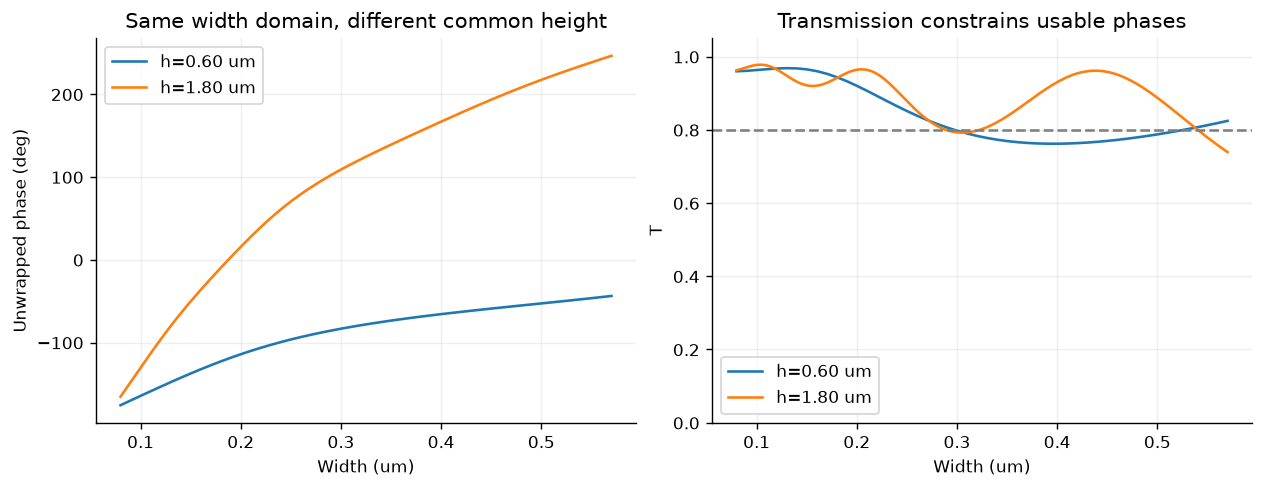

In [2]:
screen=[]
for height in HEIGHT_CANDIDATES:
    values=[solve_cell(replace(REFERENCE,width_um=float(w),height_um=height),16) for w in SCREEN_WIDTHS]
    t=np.array([v['t'][16] for v in values]);power=np.array([v['T_total'] for v in values])
    screen.append(dict(height_um=height,phase_span_deg=float(np.rad2deg(np.ptp(np.unwrap(np.angle(t))))),minimum_T=float(power.min()),fraction_above_threshold=float(np.mean(power>=MINIMUM_T))))
table(['Height (um)','Sampled phase span (deg)','Minimum T','Fraction with T >= 0.8'],[[r[k] for k in ['height_um','phase_span_deg','minimum_T','fraction_above_threshold']] for r in screen])
extended=[]
for width in WIDTHS:
    c=replace(REFERENCE,height_um=EXTENDED_HEIGHT_UM,width_um=float(width))
    a,b=solve_cell(c,M_LIBRARY),solve_cell(c,M_LIBRARY_CHECK)
    t,r=a['t'][M_LIBRARY],a['r'][M_LIBRARY]
    dt=float(abs(t-b['t'][M_LIBRARY_CHECK]));dp=float(max(abs(a['T_total']-b['T_total']),abs(a['R_total']-b['R_total'])))
    dphi=float(abs(phase_error_deg(t,b['t'][M_LIBRARY_CHECK])))
    extended.append(dict(width_um=float(width),t_real=float(t.real),t_imag=float(t.imag),r_real=float(r.real),r_imag=float(r.imag),T=a['T_total'],R=a['R_total'],phase_deg=float(np.rad2deg(np.angle(t))),delta_t=dt,delta_power=dp,delta_phase_deg=dphi,balance_error=a['balance_error'],accepted=bool(dt<5e-4 and dp<5e-4 and dphi<.05 and a['balance_error']<1e-8)))
assert all(r['accepted'] for r in extended)
original=json.loads((ROOT/'data/chapter-03/response-library.json').read_text())['rows']
print('Extended library:',len(extended),'accepted rows; worst complex refinement',max(r['delta_t'] for r in extended))
fig,axes=plt.subplots(1,2,figsize=(10,3.8),layout='constrained')
for rows,label in [(original,'h=0.60 um'),(extended,'h=1.80 um')]:
    width=[r['width_um'] for r in rows];t=np.array([complex(r['t_real'],r['t_imag']) for r in rows])
    axes[0].plot(width,np.rad2deg(np.unwrap(np.angle(t))),label=label)
    axes[1].plot(width,[r['T'] for r in rows],label=label)
axes[0].set(xlabel='Width (um)',ylabel='Unwrapped phase (deg)',title='Same width domain, different common height')
axes[1].axhline(MINIMUM_T,color='gray',ls='--');axes[1].set(xlabel='Width (um)',ylabel='T',ylim=(0,1.05),title='Transmission constrains usable phases')
for ax in axes:ax.legend();ax.grid(alpha=.2)
plt.show()

## 2. Quantize a ramp and select actual geometries

The target $\phi_j=2\pi(j+1/2)/N+\phi_0$ produces positive order $m=+1$ under
our Fourier convention. At each candidate global offset, choose the nearest
circular phase among accepted rows with $T\geq0.8$. Minimize the **mean squared
phase error** across the six positions over a fixed 361-offset grid. The global
offset changes which geometries are selected, although adding a constant to an
ideal continuous phase profile does not change its beam direction.

In [3]:
def choose(rows):
    trials=[]
    for offset in np.linspace(-np.pi,np.pi,361,endpoint=False):
        selected,error=select_widths(rows,target_phases,MINIMUM_T,float(offset))
        trials.append((float(np.mean(error**2)),float(offset),selected,error))
    score,offset,selected,error=min(trials,key=lambda x:x[0])
    return dict(offset_rad=offset,selected=selected,errors_deg=np.rad2deg(error).tolist(),rms_phase_error_deg=float(np.rad2deg(np.sqrt(score))))
limited,expanded=choose(original),choose(extended)
table(['Library height (um)','Global offset (deg)','RMS phase error (deg)','Maximum error (deg)','All targets within 5 deg'],[[height,np.rad2deg(v['offset_rad']),v['rms_phase_error_deg'],max(abs(np.array(v['errors_deg']))),bool(max(abs(np.array(v['errors_deg'])))<=PHASE_ACCEPT_DEG)] for height,v in [(.6,limited),(1.8,expanded)]])
table(['Position','Width (um)','Local T','Phase error (deg)'],[[j,r['width_um'],r['T'],expanded['errors_deg'][j]] for j,r in enumerate(expanded['selected'])])
assert max(abs(np.array(expanded['errors_deg'])))<PHASE_ACCEPT_DEG

Library height (um),Global offset (deg),RMS phase error (deg),Maximum error (deg),All targets within 5 deg
0.6,-111.1911,50.47282,85.41668,False
1.8,-67.31302,0.380641,0.6171583,True


Position,Width (um),Local T,Phase error (deg)
0,0.159625,0.920416,0.3932993
1,0.2055625,0.9653915,-0.2418766
2,0.26375,0.8426599,-0.2701885
3,0.355625,0.8473579,-0.3847026
4,0.4689375,0.9408468,0.2329258
5,0.1198125,0.9654266,0.6171583


## 3. Compare a local mask with a full-wave supercell

The local prediction assumes a constant complex field coefficient in each
pitch-wide interval. Its exact Fourier coefficient includes the finite sample
width: $C_m=\operatorname{sinc}(m/N)N^{-1}\sum_j t_j e^{-2\pi i m(j+1/2)/N}$.
Using $\mathrm{Re}(q_{t,m})|C_m|^2/q_{i,0}$ gives a **local-mask power estimate**.
It need not conserve energy because neighboring elements and boundary matching
were not solved together. The RCWA supercell instead matches Maxwell fields
for the complete repeated geometry. It includes all open orders on both sides.

Design,"T(+1), incident-normalized",T(+1)/Ttotal,Local-mask T(+1),Rtotal,Ttotal,Local R+T
limited,0.3862481,0.4437,0.3525038,0.1294836,0.8705164,0.9012286
expanded,0.8553566,0.9385158,0.8027336,0.08860715,0.9113928,0.8822492
uniform,7.525583e-31,9.382007e-31,1.309617e-32,0.1978706,0.8021294,1
reversed,0.01393317,0.01528778,8.511829e-05,0.08860715,0.9113928,0.8822492


Order,R,T,Local R estimate,Local T estimate,Delta T: 144 to 192
-3,0,0.005079168,0,3.415748e-05,1.322934e-06
-2,0.0005844547,0.004176759,0.0005302687,2.415145e-05,9.809892e-07
-1,0.001480109,0.01393317,0.002041901,8.511829e-05,4.156977e-07
0,0.07579788,0.01711352,0.07273119,0.0002863092,8.545225e-07
1,0.001387779,0.8553566,0.001078678,0.8027336,1.423393e-06
2,0.009356926,0.008100732,0.002556111,0.0001135928,5.959918e-07
3,0,0.007632931,0,3.415748e-05,1.112877e-06


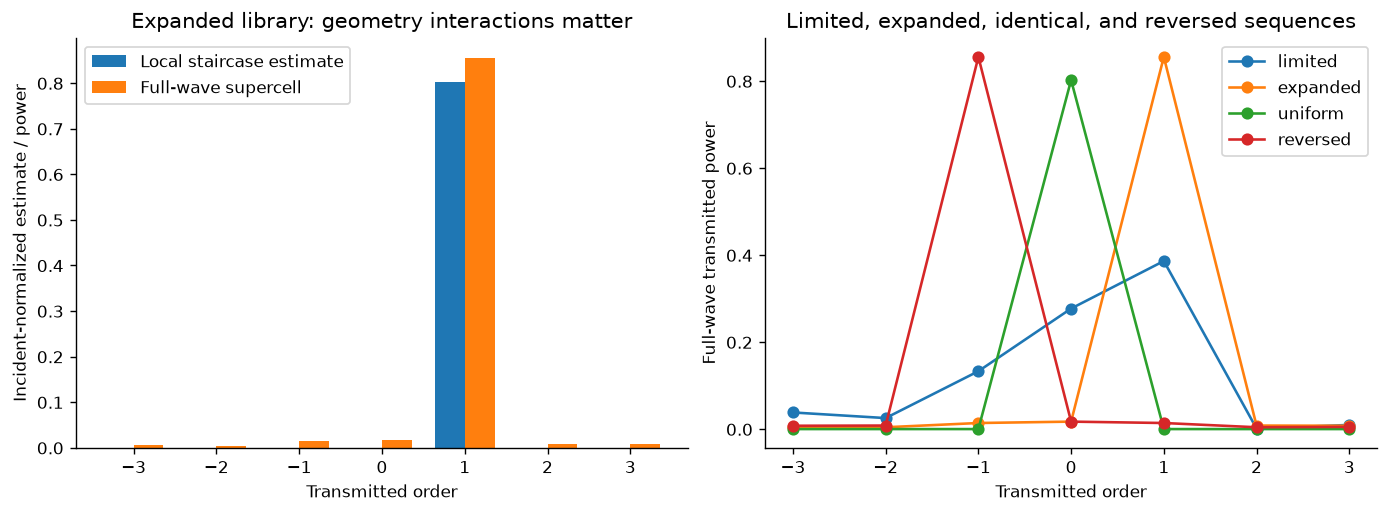

In [4]:
case_specs=[('limited',.6,limited['selected']),('expanded',1.8,expanded['selected']),
            ('uniform',1.8,[min(extended,key=lambda r:abs(r['width_um']-.325))]*N_CELLS),
            ('reversed',1.8,expanded['selected'][::-1])]
cases=[];raw={}
for name,height,selected in case_specs:
    widths=[r['width_um'] for r in selected]
    result=solve_supercell(widths,pitch_um=PITCH_UM,height_um=height,wavelength_um=WAVELENGTH_UM,n_substrate=N_OUTPUT,half_order=M_FINAL)
    check=solve_supercell(widths,pitch_um=PITCH_UM,height_um=height,wavelength_um=WAVELENGTH_UM,n_substrate=N_OUTPUT,half_order=M_CHECK)
    ct=staircase_coefficients([complex(r['t_real'],r['t_imag']) for r in selected],result['orders'])
    cr=staircase_coefficients([complex(r['r_real'],r['r_imag']) for r in selected],result['orders'])
    lpaT=result['qt'].real/result['qi'][M_FINAL].real*abs(ct)**2
    lpaR=result['qi'].real/result['qi'][M_FINAL].real*abs(cr)**2
    open_either=(result['qi'].real>0)|(result['qt'].real>0)
    rows=[]
    for index in np.where(open_either)[0]:
        m=int(result['orders'][index]);j=m+M_CHECK
        rows.append(dict(m=m,reflection_open=bool(result['qi'][index].real>0),transmission_open=bool(result['qt'][index].real>0),R=float(result['R'][index]),T=float(result['T'][index]),local_R=float(lpaR[index]),local_T=float(lpaT[index]),t_real=float(result['t'][index].real),t_imag=float(result['t'][index].imag),delta_T=float(abs(result['T'][index]-check['T'][j])),delta_R=float(abs(result['R'][index]-check['R'][j])),delta_complex_t=float(abs(result['t'][index]-check['t'][j]))))
    assert max(r['delta_T'] for r in rows)<1e-4 and max(r['delta_R'] for r in rows)<1e-4
    assert max(r['delta_complex_t'] for r in rows if r['transmission_open'])<1e-4
    assert result['balance_error']<1e-8
    target=next(r for r in rows if r['m']==1)
    record=dict(name=name,height_um=height,widths_um=widths,local_t=[[r['t_real'],r['t_imag']] for r in selected],orders=rows,R_total=result['R_total'],T_total=result['T_total'],target_T=target['T'],conditional_target_fraction=target['T']/result['T_total'],local_target_T=target['local_T'],local_balance=float(lpaT.sum()+lpaR.sum()),balance_error=result['balance_error'])
    cases.append(record);raw[name]=result
table(['Design','T(+1), incident-normalized','T(+1)/Ttotal','Local-mask T(+1)','Rtotal','Ttotal','Local R+T'],[[v[k] for k in ['name','target_T','conditional_target_fraction','local_target_T','R_total','T_total','local_balance']] for v in cases])
table(['Order','R','T','Local R estimate','Local T estimate','Delta T: 144 to 192'],[[r[k] for k in ['m','R','T','local_R','local_T','delta_T']] for r in cases[1]['orders']])
assert cases[2]['target_T']<1e-12
assert abs(next(r['T'] for r in cases[3]['orders'] if r['m']==-1)-cases[1]['target_T'])<1e-10
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
orders=[r['m'] for r in cases[1]['orders']]
axes[0].bar(np.array(orders)-.18,[r['local_T'] for r in cases[1]['orders']],width=.36,label='Local staircase estimate')
axes[0].bar(np.array(orders)+.18,[r['T'] for r in cases[1]['orders']],width=.36,label='Full-wave supercell')
axes[0].set(xlabel='Transmitted order',ylabel='Incident-normalized estimate / power',title='Expanded library: geometry interactions matter');axes[0].legend()
for case in cases:axes[1].plot(orders,[r['T'] for r in case['orders']],'o-',label=case['name'])
axes[1].set(xlabel='Transmitted order',ylabel='Full-wave transmitted power',title='Limited, expanded, identical, and reversed sequences');axes[1].legend()
plt.show()

## 4. Refine the Fourier bandwidth

As a supercell grows, keeping the same integer $M$ reduces the maximum represented
physical transverse wavevector. The calculation below holds the six-cell geometry
fixed and refines $M$. The final 144/192 comparison is already applied to every
reported open-order power and complex transmitted amplitude for all four cases.
Power conservation and convergence are reported independently.

In [5]:
convergence=[]
for M in [12,24,36,48,72,96,144]:
    result=solve_supercell(cases[1]['widths_um'],height_um=1.8,half_order=M)
    convergence.append(dict(M=M,harmonics=2*M+1,target_T=float(result['T'][M+1]),delta_target_vs_192=0.,balance_error=result['balance_error']))
# Use a fresh explicit high-order target for signed-difference-independent errors.
high=solve_supercell(cases[1]['widths_um'],height_um=1.8,half_order=M_CHECK)
for row in convergence:row['delta_target_vs_192']=abs(row['target_T']-float(high['T'][M_CHECK+1]))
table(['M','Harmonics','T(+1)','Difference vs M=192','Power residual'],[[r[k] for k in ['M','harmonics','target_T','delta_target_vs_192','balance_error']] for r in convergence])

M,Harmonics,T(+1),Difference vs M=192,Power residual
12,25,0.8383331,0.01702204,5.551115e-16
24,49,0.8564049,0.001049789,4.440892e-16
36,73,0.8555819,0.0002267418,0
48,97,0.8554351,8.000057e-05,3.330669e-16
72,145,0.8553768,2.169564e-05,3.330669e-16
96,193,0.855367,1.180815e-05,4.440892e-16
144,289,0.8553566,1.423393e-06,1.110223e-15


## 5. Reconstruct the deflected field

The plot covers two repeated supercells and uses the full modal solution at
$M=144$. It illustrates the coherent field, including interference and near-field
structure. The separately computed modal powers establish the far-field order
fractions. This picture does not model an aperture edge or a finite incident beam.

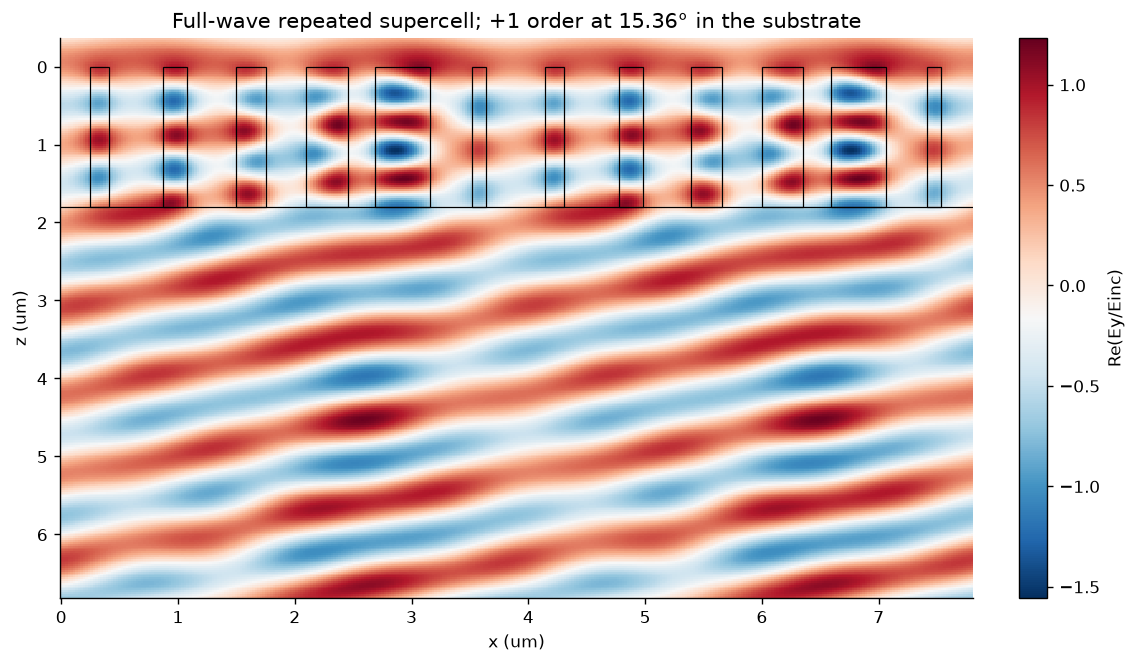

In [6]:
result=raw['expanded']
x=np.linspace(0,2*PERIOD_UM,361);z=np.linspace(-.35,1.8+5,301)
field=sample_ey(result['cell'],result,x,z)
fig,ax=plt.subplots(figsize=(9,5.2),layout='constrained')
image=ax.pcolormesh(x,z,field.real,shading='auto',cmap='RdBu_r');fig.colorbar(image,ax=ax,label='Re(Ey/Einc)')
for repeat in [0,1]:
    for center,width in zip(centers+repeat*PERIOD_UM,cases[1]['widths_um']):ax.add_patch(plt.Rectangle((center-width/2,0),width,1.8,fill=False,color='black',lw=.7))
ax.axhline(1.8,color='black',lw=.7);ax.invert_yaxis();ax.set(xlabel='x (um)',ylabel='z (um)',title=f'Full-wave repeated supercell; +1 order at {target_angle:.2f}° in the substrate')
plt.show()

## 6. Export a reproducible synthesis record

The JSON preserves the extended library, phase-offset selection, geometry
sequences, full-wave and local-mask order powers, convergence, source hashes,
and validity limits. The separate audit script adds identical-cell embedding,
mirror reversal, fine-order checks, and grcwa raster refinements. The chosen
performance belongs to this ideal, infinitely periodic, lossless TE geometry.
No broadband, fabrication, finite-device, or independent FEM/FDTD validation
is implied.

In [7]:
metadata=dict(topic_id='ms-05-beam-steering',solver=SOLVER_VERSION,units='micrometers/degrees',time_convention='exp(-i omega t)',spatial_convention='exp(i k.r)',phase_references={'r':'z=0','t':'z=common height'},pitch_um=PITCH_UM,period_um=PERIOD_UM,wavelength_um=WAVELENGTH_UM,n_incident=1.,n_substrate=N_OUTPUT,n_ridge=2.4,n_gap=1.,target_order=1,target_angle_deg=target_angle,half_order=M_FINAL,check_half_order=M_CHECK,library_half_order=M_LIBRARY,library_check_half_order=M_LIBRARY_CHECK,minimum_T=MINIMUM_T,selection='361 fixed global offsets; minimize circular phase RMS using unit-cell data only',source_sha256={name:hashlib.sha256((ROOT/'simulations'/name).read_bytes()).hexdigest() for name in ['unit_cell_te.py','metasurface_synthesis.py']},environment=dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__),limits=['1D TE, real constant dielectric indices','Infinite periodic supercell','Common ridge height within each design','No FEM/FDTD or experiment','Focusing and polarization are separate scalar/Jones models'])
output=dict(metadata=metadata,height_screen=screen,extended_library=extended,selection={name:{k:v for k,v in choice.items() if k!='selected'} for name,choice in [('limited',limited),('expanded',expanded)]},cases=cases,convergence=convergence)
(DATA/'beam-steering.json').write_text(json.dumps(output,indent=2)+'\n',encoding='utf-8')
with (DATA/'extended-library.csv').open('w',newline='',encoding='utf-8') as handle:
    writer=csv.DictWriter(handle,fieldnames=list(extended[0]));writer.writeheader();writer.writerows(extended)
print('Saved beam-steering.json and extended-library.csv')
print('Expanded target-order power:',cases[1]['target_T'],'conditional transmitted fraction:',cases[1]['conditional_target_fraction'])

Saved beam-steering.json and extended-library.csv
Expanded target-order power: 0.8553565666096787 conditional transmitted fraction: 0.9385157769011392


## Interpretation and exercises

Explain why the allowed positive order has zero amplitude for identical ridges.
Explain why reversing the sequence reverses the strong outgoing order. Compare
incident-normalized power and power conditional on transmission. Identify where
the local mask's power account differs from the Maxwell result. Change a target
order or period and redo order enumeration and convergence. Evaluate a changed
geometry with a fresh solve rather than treating it as a verified prediction.

References: [Yu et al. (2011)](https://doi.org/10.1126/science.1210713),
[RCWA foundation](https://doi.org/10.1364/JOSA.71.000811), and
[grcwa documentation](https://grcwa.readthedocs.io/en/latest/usage.html).